In [8]:
import numpy as np
import math
import matplotlib.pyplot as plt
import random

In [19]:
### La distribuzione uniforme definita sull'intervallo [0, 1] ha pdf p(x)=1 sull'intervallo e zero al di fuori
#di [0, 1]. Il valor medio è E(x)=1/2 e la deviazione standard è s=1/sqrt(12).

a = float(input("Inserire l'estremo inferiore della distribuzione uniforme: "))
b = float(input("Inserire l'estremo superiore della distribuzione uniforme: "))

sizes_array = np.arange(10, 1000000, 100)
means_array = []
vars_array = []
abs_mean_errs = []
abs_dev_errs = []

rel_mean_errs=[]
rel_dev_errs=[]

for size in sizes_array:
    random_array = np.random.uniform(float(a), float(b), size)
    s=0
    s2=0
    em=0
    rm=0
    ed=0
    rd=0
    for i in range(len(random_array)):
        s=s+random_array[i]
        s2=s2+random_array[i]**2
    mean_batch = s/size
    var_batch = 1/(size-1)*(s2-size*mean_batch**2)
    means_array.append(mean_batch)
    vars_array.append(var_batch)

    abs_mean_errs.append(abs(mean_batch-((a+b)/2)))
    rel_mean_errs.append((1/((a+b)/2))*abs(mean_batch-((a+b)/2)))

    abs_dev_errs.append(abs(np.sqrt(var_batch)-((b-a)/np.sqrt(12))))
    rel_dev_errs.append(1/(np.sqrt(var_batch))*abs(np.sqrt(var_batch)-((b-a)/np.sqrt(12))))

means_array=np.array(means_array)
vars_array=np.array(vars_array)
abs_mean_errs=np.array(abs_mean_errs)
rel_mean_errs=np.array(rel_mean_errs)
abs_dev_errs=np.array(abs_dev_errs)
rel_dev_errs=np.array(rel_dev_errs)


Inserire l'estremo inferiore della distribuzione uniforme:  0
Inserire l'estremo superiore della distribuzione uniforme:  1


In [20]:
def double_hist(X1, Y1, X2, Y2, title1, title2, xlab1, ylab1, xlab2, ylab2, hline1=None, hline2=None):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))

    ax[0].plot(X1, Y1, color="blue")
    ax[0].set_title(str(title1), fontsize=20)
    ax[0].set_xlabel(str(xlab1), fontsize=20)
    ax[0].set_ylabel(str(ylab1), fontsize=20)
    ax[0].grid(True)

    if hline1 is not None:
        ax[0].axhline(y=hline1, color="black", linestyle="--", linewidth=2, 
                      label=rf"$\mu = \frac{{{a+b}}}{{2}}$ - true mean value")
    ax[0].legend(fontsize=15)
    ax[0].set_xscale("log")
    
    ax[1].plot(X2, Y2, color="red")
    ax[1].set_title(str(title2), fontsize=20)
    ax[1].set_xlabel(str(xlab2), fontsize=20)
    ax[1].set_ylabel(str(ylab2), fontsize=20)
    ax[1].grid(True)
    if hline2 is not None:
        ax[1].axhline(y=hline2, color="black", linestyle="--", linewidth=2, 
                      label=rf"$\sigma^2 = \frac{{{(b-a)**2}}}{{12}}$ - true variance value")
    ax[1].legend(fontsize=15)
    ax[1].set_xscale("log")
    
    plt.tight_layout()
    

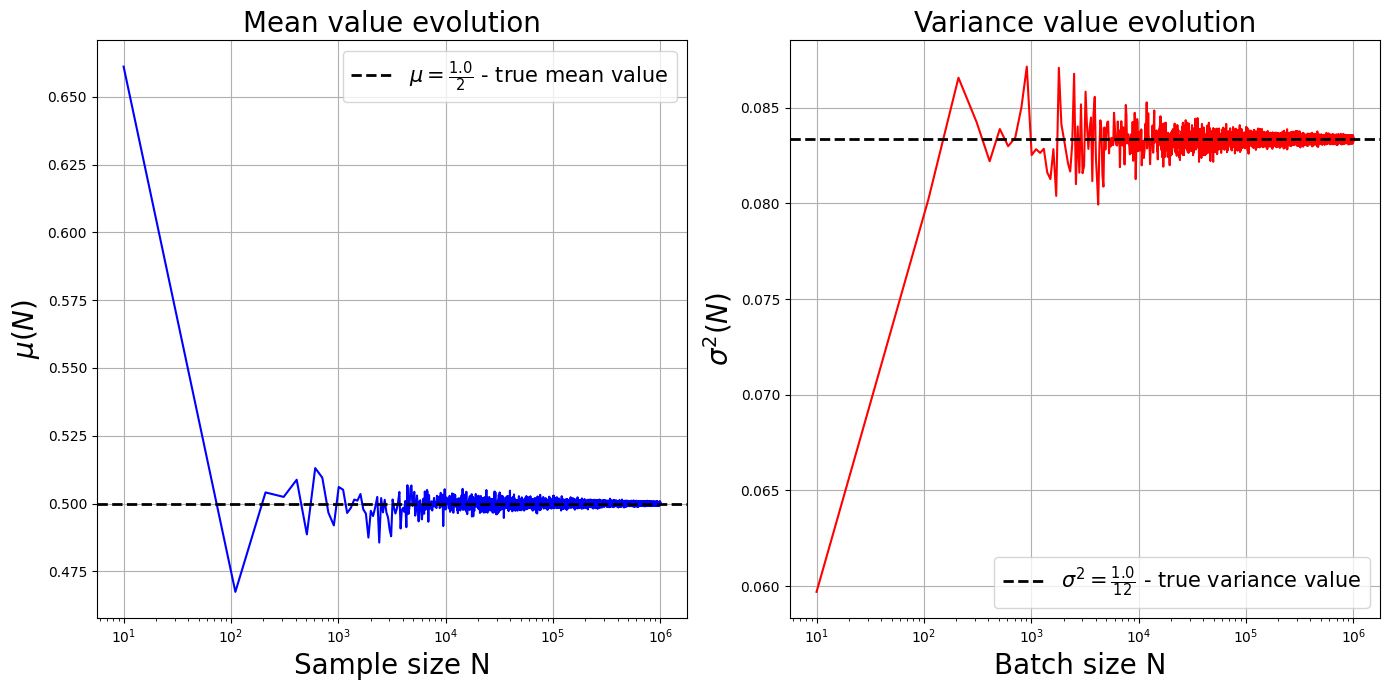

In [21]:
double_hist(sizes_array, means_array, sizes_array, vars_array,
           "Mean value evolution", "Variance value evolution", "Sample size N", "$\mu(N)$", "Batch size N ", "$\sigma^2(N)$", 
           float(a+b)/2, float((b-a)**2/12))
plt.show()

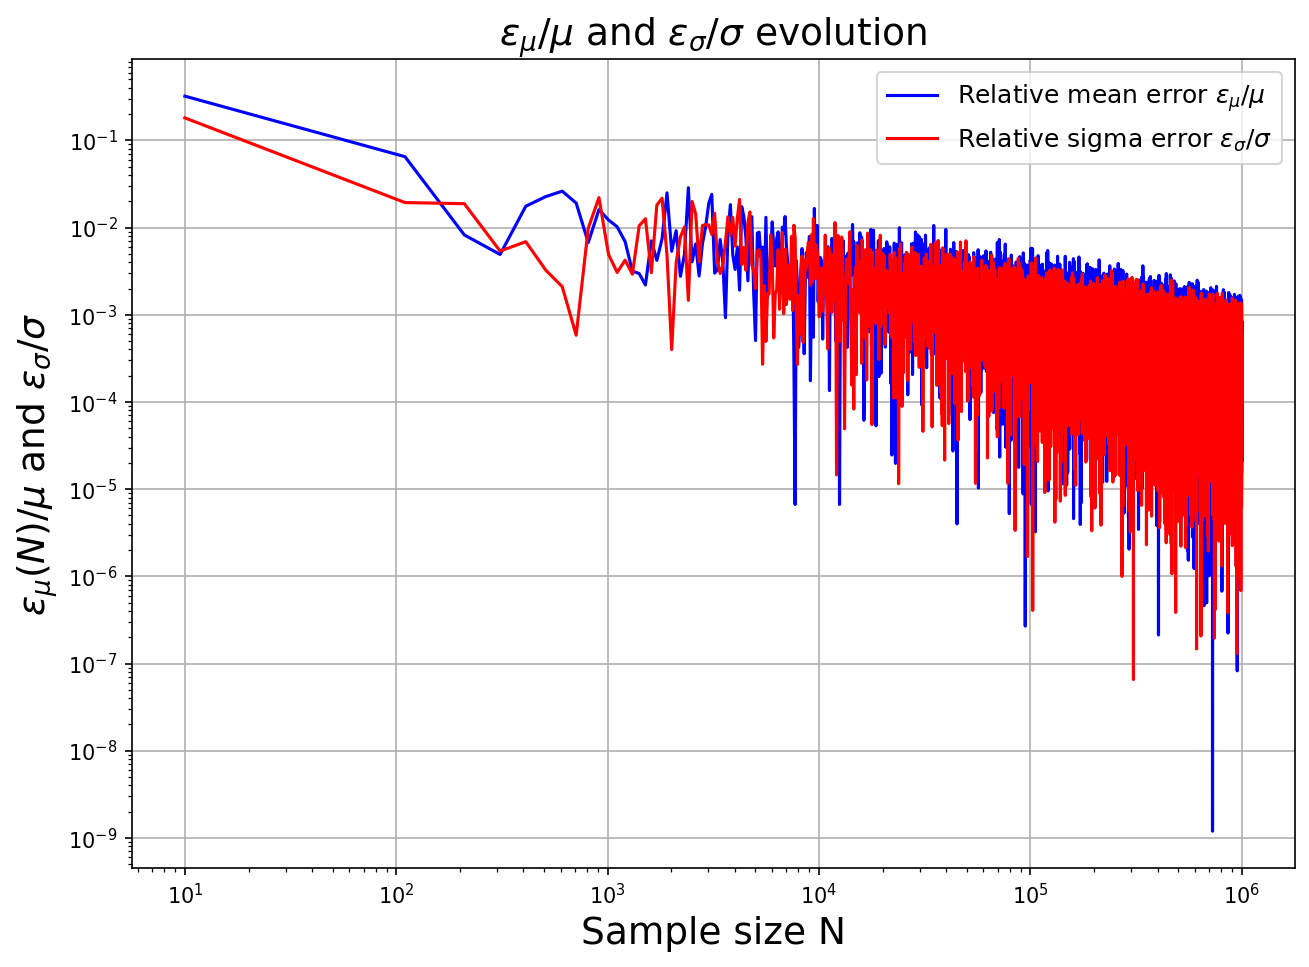

In [23]:
plt.figure(figsize=(10, 7), dpi=150)
plt.plot(sizes_array, rel_mean_errs,  color="blue", 
        label= "Relative mean error $\epsilon_{\mu}$/$\mu$")
plt.plot(sizes_array, rel_dev_errs,  color="red", 
         label= "Relative sigma error $\epsilon_{\sigma}$/$\sigma$")
plt.title("$\epsilon_{\mu}$/$\mu$ and $\epsilon_{\sigma}$/$\sigma$ evolution", fontsize=18)
plt.xlabel("Sample size N",  fontsize=18)
plt.ylabel("$\epsilon_{\mu}(N)$/$\mu$ and $\epsilon_{\sigma}$/$\sigma$", fontsize=18)
plt.xscale("log")
plt.yscale("log")
plt.legend(fontsize=12)
plt.grid(True)
plt.show()